# CO2 Emissions: Backward Elimination

Goal: predict vehicle CO2 emissions (`CO2 Emissions(g/km)`) with Multiple Linear Regression, then remove redundant features using Backward Elimination (p-value based).

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd

In [2]:
dataset=pd.read_csv("../data/CO2 Emissions_Canada.csv")


## 2. Basic inspection
Checking shape, data types, summary statistics, missing values and duplicates.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

In [4]:
dataset.shape

(7385, 12)

In [5]:
dataset.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [6]:
dataset.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,27.481652,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,7.231879,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,32.000000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


In [7]:
print(dataset.isna().sum())

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64


**Missing values:** none of the 12 columns contain missing values, so no imputation is needed.

### Duplicate rows
Duplicated rows add no new information. If one copy lands in the training set and another in the test set, the test score becomes too optimistic (data leakage). I count the extra copies and drop them **before** splitting.

In [8]:
print(dataset.duplicated().sum())

1103


In [9]:
dataset=dataset.drop_duplicates().reset_index(drop=True)
print(dataset.shape)

(6282, 12)


**Result:** found 1,103 duplicate rows; the dataset went from 7,385 to 6,282 rows after dropping them.

## 3. Feature selection

**Target:** `CO2 Emissions(g/km)`

**Features kept:**
- `Engine Size(L)`, `Cylinders`: engine characteristics (numeric).
- `Fuel Consumption City / Hwy / Comb (L/100 km)`: fuel consumption (numeric). Kept on purpose: they overlap heavily, which makes this dataset a good case for Backward Elimination.
- `Fuel Type`: categorical, will be one-hot encoded later.

**Columns dropped:**
- `Make`, `Model`: too many unique values. One-hot encoding would create hundreds of columns for ~6,000 rows, and `Model` is close to an identifier, which invites overfitting.
- `Fuel Consumption Comb (mpg)`: the same quantity as `Comb (L/100 km)` in a different unit, so it adds no new information.
- `Vehicle Class`, `Transmission`: left out to keep the exercise small.

In [10]:
dataset=dataset[['Engine Size(L)','Cylinders','Fuel Consumption City (L/100 km)','Fuel Consumption Hwy (L/100 km)','Fuel Consumption Comb (L/100 km)','Fuel Type','CO2 Emissions(g/km)']]
dataset

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Type,CO2 Emissions(g/km)
0,2.0,4,9.9,6.7,8.5,Z,196
1,2.4,4,11.2,7.7,9.6,Z,221
2,1.5,4,6.0,5.8,5.9,Z,136
3,3.5,6,12.7,9.1,11.1,Z,255
4,3.5,6,12.1,8.7,10.6,Z,244
...,...,...,...,...,...,...,...
6277,2.0,4,10.7,7.7,9.4,Z,219
6278,2.0,4,11.2,8.3,9.9,Z,232
6279,2.0,4,11.7,8.6,10.3,Z,240
6280,2.0,4,11.2,8.3,9.9,Z,232


## 4. Correlation analysis
The heatmap shows Pearson correlation between numeric columns (+1: strong positive, -1: strong negative, 0: no linear relationship). `Fuel Type` is categorical, so it is one-hot encoded **for this plot only**.

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
dataset_encoded=pd.get_dummies(dataset,columns=['Fuel Type'])
corr=dataset_encoded.corr(numeric_only=True)
corr


,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),CO2 Emissions(g/km),Fuel Type_D,Fuel Type_E,Fuel Type_N,Fuel Type_X,Fuel Type_Z
Engine Size(L),1.000000,0.928843,0.834228,0.766817,0.820146,0.854802,-0.071343,0.169407,0.004050,-0.230486,0.177520
Cylinders,0.928843,1.000000,0.801277,0.717647,0.781099,0.834687,-0.058169,0.120497,0.002605,-0.303486,0.269017
Fuel Consumption City (L/100 km),0.834228,0.801277,1.000000,0.950811,0.994052,0.918756,-0.115534,0.456065,0.009198,-0.312780,0.144863
Fuel Consumption Hwy (L/100 km),0.766817,0.717647,0.950811,1.000000,0.978607,0.883424,-0.122725,0.488140,0.002378,-0.246896,0.066485
Fuel Consumption Comb (L/100 km),0.820146,0.781099,0.994052,0.978607,1.000000,0.916840,-0.119154,0.472362,0.007203,-0.293165,0.118945
CO2 Emissions(g/km),0.854802,0.834687,0.918756,0.883424,0.916840,1.000000,-0.041566,0.098858,-0.008121,-0.247861,0.217960
Fuel Type_D,-0.071343,-0.058169,-0.115534,-0.122725,-0.119154,-0.041566,1.000000,-0.036448,-0.001953,-0.149845,-0.137250
Fuel Type_E,0.169407,0.120497,0.456065,0.488140,0.472362,0.098858,-0.036448,1.000000,-0.002971,-0.227938,-0.208779
Fuel Type_N,0.004050,0.002605,0.009198,0.002378,0.007203,-0.008121,-0.001953,-0.002971,1.000000,-0.012215,-0.011188
Fuel Type_X,-0.230486,-0.303486,-0.312780,-0.246896,-0.293165,-0.247861,-0.149845,-0.227938,-0.012215,1.000000,-0.858328


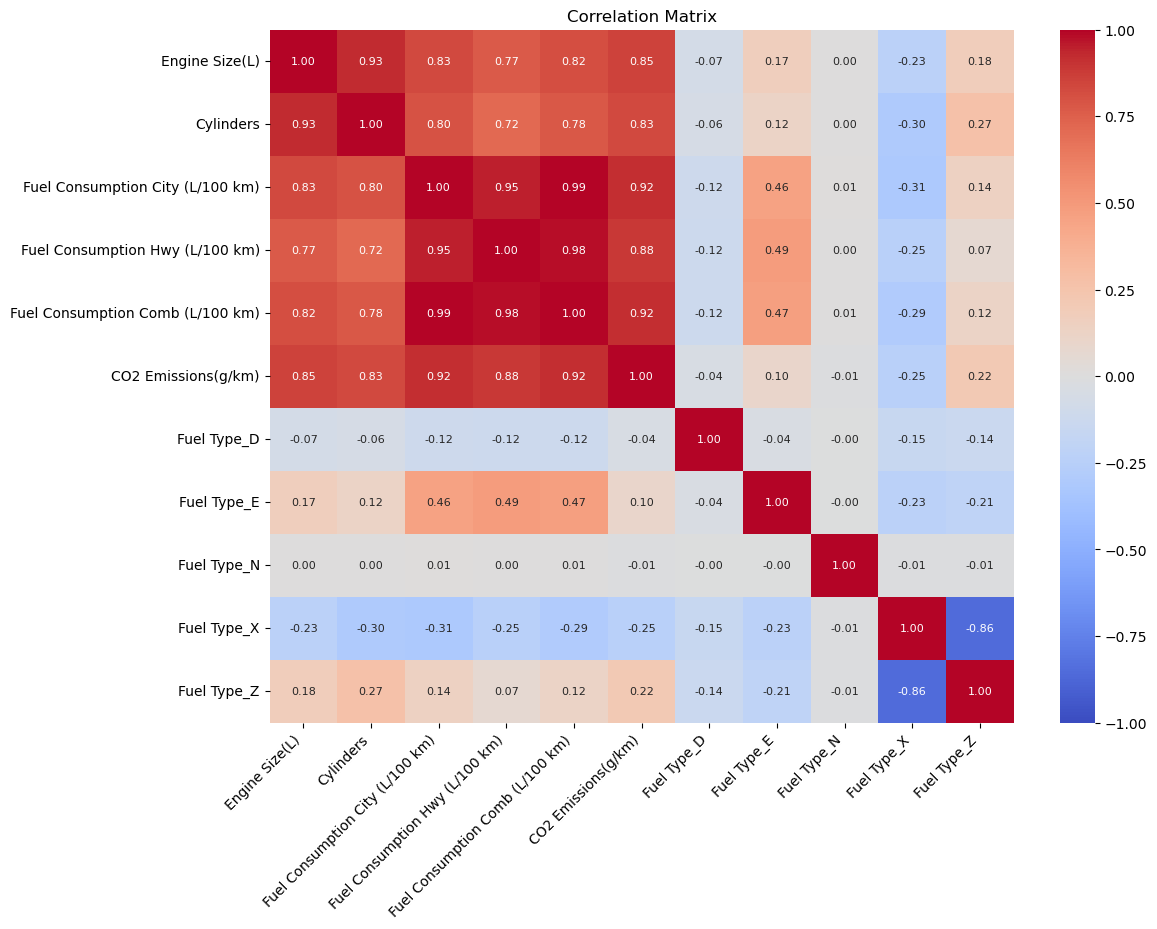

In [12]:
plt.figure(figsize=(12,9))
sns.heatmap(corr,annot=True,annot_kws={'size':8},cmap='coolwarm',fmt='.2f',vmax=1,vmin=-1)
plt.xticks(rotation=45,ha='right')
plt.title("Correlation Matrix")
plt.show()

**Findings:**
- CO2 emissions correlate most strongly with fuel consumption (City ≈ 0.92, Comb ≈ 0.92, Hwy ≈ 0.88), followed by `Engine Size(L)` (≈ 0.85) and `Cylinders` (≈ 0.83).
- City, Hwy and Comb fuel consumption are almost perfectly correlated with each other (City vs Comb ≈ 0.99), because combined consumption is derived from the other two.
- `Engine Size(L)` and `Cylinders` are also strongly correlated (≈ 0.93).
- Each `Fuel Type` dummy has a weak linear correlation with CO2 (|r| ≤ 0.25). `Fuel Type_X` and `Fuel Type_Z` are strongly negatively correlated (≈ -0.86) since most rows belong to one of the two, which is why one dummy column must be dropped during encoding (`drop='first'`) to avoid the dummy variable trap.
- I expect multicollinearity to show up in the OLS summary later; we will see which features Backward Elimination removes.

## 5. Rare category handling
`Fuel Type = N` (natural gas) has only 1 row(s) in the dataset. With so few examples the model cannot learn a reliable coefficient, and a random split can place all of them in the test set, which breaks the encoder because the category is unseen during `fit`. I drop these rows before splitting. This does not cause data leakage, since it uses only the feature value, not the target or the test set.

In [13]:
n_rows = (dataset['Fuel Type'] == 'N').sum()
print(f"Rows with Fuel Type N: {n_rows}")

dataset = dataset[dataset['Fuel Type'] != 'N'].reset_index(drop=True)
print(dataset.shape)

Rows with Fuel Type N: 1
(6281, 7)


In [14]:
X=dataset.drop(columns=['CO2 Emissions(g/km)'])
y=dataset['CO2 Emissions(g/km)']
X
y

0       196
1       221
2       136
3       255
4       244
       ... 
6276    219
6277    232
6278    240
6279    232
6280    248
Name: CO2 Emissions(g/km), Length: 6281, dtype: int64

## 6. Train/test split and encoding
- Split first (80% train / 20% test, `random_state=42`), then fit the encoder **on the training set only**, so no information from the test set leaks into preprocessing.
- `Fuel Type` is one-hot encoded with `OneHotEncoder(drop='first')` inside a `ColumnTransformer`. Dropping the first category avoids the dummy variable trap (perfect multicollinearity between the dummy columns).
- Numeric columns are passed through unchanged. Linear Regression does not need feature scaling.

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)

(5024, 6)
(1257, 6)


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct=ColumnTransformer(transformers=[("encoder",OneHotEncoder(drop='first',sparse_output=False),['Fuel Type'])],remainder='passthrough')
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)

**Result:** the training set has 5,024 rows and the test set has 1,257 rows. After encoding there are 8 feature columns (3 `Fuel Type` dummies + 5 numeric features).

## 7. Baseline model: Linear Regression with all features
Fit a `LinearRegression` on all features. This is the reference to compare against after Backward Elimination.

In [17]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Predictions vs actual values
The first 10 test predictions next to the true CO2 values.

In [18]:
y_pred=regressor.predict(X_test)
pd.DataFrame({'Actual':y_test.values,'Predicted':y_pred}).head(10)

,Actual,Predicted
0,298,322.229716
1,296,292.258818
2,300,296.594913
3,275,271.146024
4,267,264.535747
5,220,217.878248
6,284,281.102792
7,239,240.538871
8,263,258.510365
9,306,309.394154


In [19]:
from sklearn.metrics import r2_score,mean_absolute_error,root_mean_squared_error
r2=r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=root_mean_squared_error(y_test,y_pred)
print(r2)
print(mae)
print(rmse)

0.9915964728408724
3.2089691458287706
5.5459771775629685


### Evaluation
**Baseline results (test set):**
- R²: 0.9916
- MAE: 3.21 g/km
- RMSE: 5.55 g/km

The baseline already explains about 99% of the variance in CO2 emissions, and the average error is about 3 g/km. RMSE is larger than MAE, so a few vehicles have bigger errors (for example the first test row: 298 actual vs 322 predicted). This is the reference for the Backward Elimination step.

### Feature names
Saving the column names after encoding. They are needed to track which features get removed during Backward Elimination, because `X_train` is now a NumPy array without column names.

In [20]:
feature_names=ct.get_feature_names_out()
feature_names

array(['encoder__Fuel Type_E', 'encoder__Fuel Type_X',
       'encoder__Fuel Type_Z', 'remainder__Engine Size(L)',
       'remainder__Cylinders',
       'remainder__Fuel Consumption City (L/100 km)',
       'remainder__Fuel Consumption Hwy (L/100 km)',
       'remainder__Fuel Consumption Comb (L/100 km)'], dtype=object)

In [22]:
import statsmodels.api as sm
names=[n.split('__')[1] for n in feature_names]
X_train_df=pd.DataFrame(X_train,columns=names,index=y_train.index)
X_opt= sm.add_constant(X_train_df)
ols=sm.OLS(y_train,X_opt).fit()
print(ols.summary())

                             OLS Regression Results                            
Dep. Variable:     CO2 Emissions(g/km)   R-squared:                       0.991
Model:                             OLS   Adj. R-squared:                  0.991
Method:                  Least Squares   F-statistic:                 6.708e+04
Date:                 Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                         10:43:51   Log-Likelihood:                -15851.
No. Observations:                 5024   AIC:                         3.172e+04
Df Residuals:                     5015   BIC:                         3.178e+04
Df Model:                            8                                         
Covariance Type:             nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

## 8. Backward Elimination (statsmodels OLS)
Starting from all 8 features (plus a constant), I repeatedly fitted an OLS model on the **training set** and removed the feature with the highest p-value until all p-values were ≤ 0.05.

**Removed (in order):**
1. `Engine Size(L)` (p = 0.1118)

**Selected features (7):** `Fuel Type_E`, `Fuel Type_X`, `Fuel Type_Z`, `Cylinders`, and the City / Hwy / Comb fuel consumption columns.

**Observations:**
- Only one feature was removed. Given `Cylinders` and the fuel consumption columns, `Engine Size(L)` adds no statistically significant information (it is strongly correlated with `Cylinders`, ≈ 0.93).
- City, Hwy and Comb consumption all stayed (p < 0.001), but their standard errors (0.88 to 1.94) are much larger than that of `Cylinders` (0.08). This is a sign of multicollinearity: the three columns share information, so their individual coefficients are unstable. Their combined effect is more meaningful: +1 L/100 km in all three adds about 22 g/km of CO2, close to the ~23 g/km expected from burning gasoline (≈ 2.3 kg CO2 per liter).
- `Fuel Type` coefficients are relative to the dropped baseline category, diesel (`D`).
- The residuals are heavy-tailed (kurtosis ≈ 37), so p-values should be interpreted with some caution.
- The p-value criterion measures statistical significance, not redundancy, which is why highly correlated features can survive.

In [24]:
threshold=0.05
X_opt=sm.add_constant(X_train_df)
removed=[]

while True:
    ols=sm.OLS(y_train,X_opt).fit()
    pvalues=ols.pvalues.drop('const')
    worst_feature=pvalues.idxmax()
    worst_p=pvalues.max()

    if(worst_p>threshold):
        removed.append((worst_feature,worst_p))
        print(f"removing {worst_feature} (p_value = {worst_p:.4f})")
        X_opt=X_opt.drop(columns=[worst_feature])
    else:
        break
selected_features=[c for c in X_opt.columns if c!= 'const']
print("Selected features :",selected_features)
print(ols.summary())

removing Engine Size(L) (p_value = 0.1118)
Selected features : ['Fuel Type_E', 'Fuel Type_X', 'Fuel Type_Z', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)']
                             OLS Regression Results                            
Dep. Variable:     CO2 Emissions(g/km)   R-squared:                       0.991
Model:                             OLS   Adj. R-squared:                  0.991
Method:                  Least Squares   F-statistic:                 7.664e+04
Date:                 Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                         11:08:37   Log-Likelihood:                -15852.
No. Observations:                 5024   AIC:                         3.172e+04
Df Residuals:                     5016   BIC:                         3.177e+04
Df Model:                            7                                         
Covariance Type:             nonrobust             